In [1]:
import requests
from datetime import datetime, timedelta
import holidays
import pandas as pd
import matplotlib.pyplot as plt
import os

# 한글 폰트 설정
plt.rcParams['font.family'] = 'NanumGothic'

# 주차장 주차가능면수 정보
param_info = {
    'id'    :   '주차장 ID',
    'gnrl'  :   '일반 잔여 주차구역 개수',
    'lgvh'  :   '경차 잔여 주차구역 개수',
    'hvvh'  :   '대형 잔여 주차구역 개수',
    'emvh'  :   '긴급차량 잔여 주차구역 개수',
    'hndc'  :   '장애인 잔여 주차구역 개수',
    'wmon'  :   '여성전용 잔여 주차구역 개수',
    'etc'   :   '기타 잔여 주차구역 개수'
}

# 사용자가 지정한 데이터 가져오기 간격 (일 단위)
data_fetch_interval = 400  # 예시로 3일 전부터 데이터를 가져오도록 설정

# 현재 시간으로 end_date_time 설정
end_date_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# start_date_time을 data_fetch_interval 만큼 이전으로 설정
start_date_time = (datetime.now() - timedelta(days=data_fetch_interval)).strftime("%Y-%m-%d %H:%M:%S")

# API URL 설정
url = "http://dev.jinwoosi.co.kr:8083/v1/parking-lot-status"
params = {
    "start_date_time": start_date_time,
    "end_date_time": end_date_time,
    "page_number": 1,
    "number_of_rows": 600000,
    "lang": "ko"
}

# GET 요청 보내기
response = requests.get(url, params=params)

# 응답 상태 코드 확인
if response.status_code == 200:
    # JSON 응답을 파이썬 딕셔너리로 변환
    data = response.json()
    
    # 'list' 키 아래의 데이터를 DataFrame으로 변환
    if 'list' in data:
        df = pd.DataFrame(data['list'])
        print("API 응답 데이터 (DataFrame):")
        print(df)
    else:
        print("응답 데이터에 'list' 키가 없습니다.")
else:
    print(f"API 요청 실패. 상태 코드: {response.status_code}")


API 응답 데이터 (DataFrame):
                  date_time        id  gnrl  lgvh  hvvh  emvh  hndc  wmon  etc
0       2023-07-18 17:20:00  11111111   204     0     0     0     7     0    0
1       2023-07-18 17:20:00  11251813   200    16     4     0    21     0    0
2       2023-07-18 17:20:00  16488201    23    11     0     0     3     0    0
3       2023-07-18 17:20:00  16489518    66     1     0     0     2     0    0
4       2023-07-18 17:20:00  17039715   146     0     0     0     6     0    0
...                     ...       ...   ...   ...   ...   ...   ...   ...  ...
461035  2024-08-21 17:10:00  17385794   141    12     0     0    12     0    0
461036  2024-08-21 17:10:00  17435963    28     0     0     0     4     0    0
461037  2024-08-21 17:10:00  17680713    72     3     0     0     6     0    0
461038  2024-08-21 17:10:00  17759313     5     0     0     0     3     0    0
461039  2024-08-21 17:10:00  20019319    51     0     0     0     0     0    0

[461040 rows x 9 columns]


In [2]:
# 데이터 처리

# 'date_time'을 datetime 형식으로 변환
df['date_time'] = pd.to_datetime(df['date_time'])

# 요일 추가 (0=월요일, 6=일요일)
df['day_of_week'] = df['date_time'].dt.dayofweek

# 공휴일 추가
kr_holidays = holidays.KR()  # 한국의 공휴일 정보를 가져오기

# 평일/공휴일을 판단하는 함수
def determine_day_type(date):
    if date in kr_holidays:
        return 0
    elif date.weekday() >= 5:  # 토요일(5) 또는 일요일(6)인 경우
        return 0
    else:
        return 1

# 날짜별로 평일/공휴일 판단하여 열 추가 (0=공휴일, 1=평일)
df['day_type'] = df['date_time'].dt.date.apply(determine_day_type)

# id의 고유한 개수 출력
unique_id_count = df['id'].nunique()
print(f"Unique ID count: {unique_id_count}")

df

Unique ID count: 10


,date_time,id,gnrl,lgvh,hvvh,emvh,hndc,wmon,etc,day_of_week,day_type
0,2023-07-18 17:20:00,11111111,204,0,0,0,7,0,0,1,1
1,2023-07-18 17:20:00,11251813,200,16,4,0,21,0,0,1,1
2,2023-07-18 17:20:00,16488201,23,11,0,0,3,0,0,1,1
3,2023-07-18 17:20:00,16489518,66,1,0,0,2,0,0,1,1
4,2023-07-18 17:20:00,17039715,146,0,0,0,6,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
461035,2024-08-21 17:10:00,17385794,141,12,0,0,12,0,0,2,1
461036,2024-08-21 17:10:00,17435963,28,0,0,0,4,0,0,2,1
461037,2024-08-21 17:10:00,17680713,72,3,0,0,6,0,0,2,1
461038,2024-08-21 17:10:00,17759313,5,0,0,0,3,0,0,2,1


In [3]:
# 데이터 저장 함수
def save_data(df, file_path):
    
    os.makedirs(os.path.dirname(file_path), exist_ok=True)
    # 오늘 날짜와 data_fetch_interval 전 날짜 계산
    end_date = datetime.now().strftime('%Y%m%d')
    start_date = (datetime.now() - timedelta(days=data_fetch_interval)).strftime('%Y%m%d')
    
    # 파일 경로 및 파일명 설정
    file_name = f"{start_date}_to_{end_date}.csv"
    
    # 데이터프레임을 CSV 파일로 저장
    df.to_csv(file_path + file_name, index=False)
    print(f"Data saved to {file_name}")
              
# 데이터 저장 호출
save_data(df, 'data/jeju_parking_lot_data_')

Data saved to 20230718_to_20240821.csv


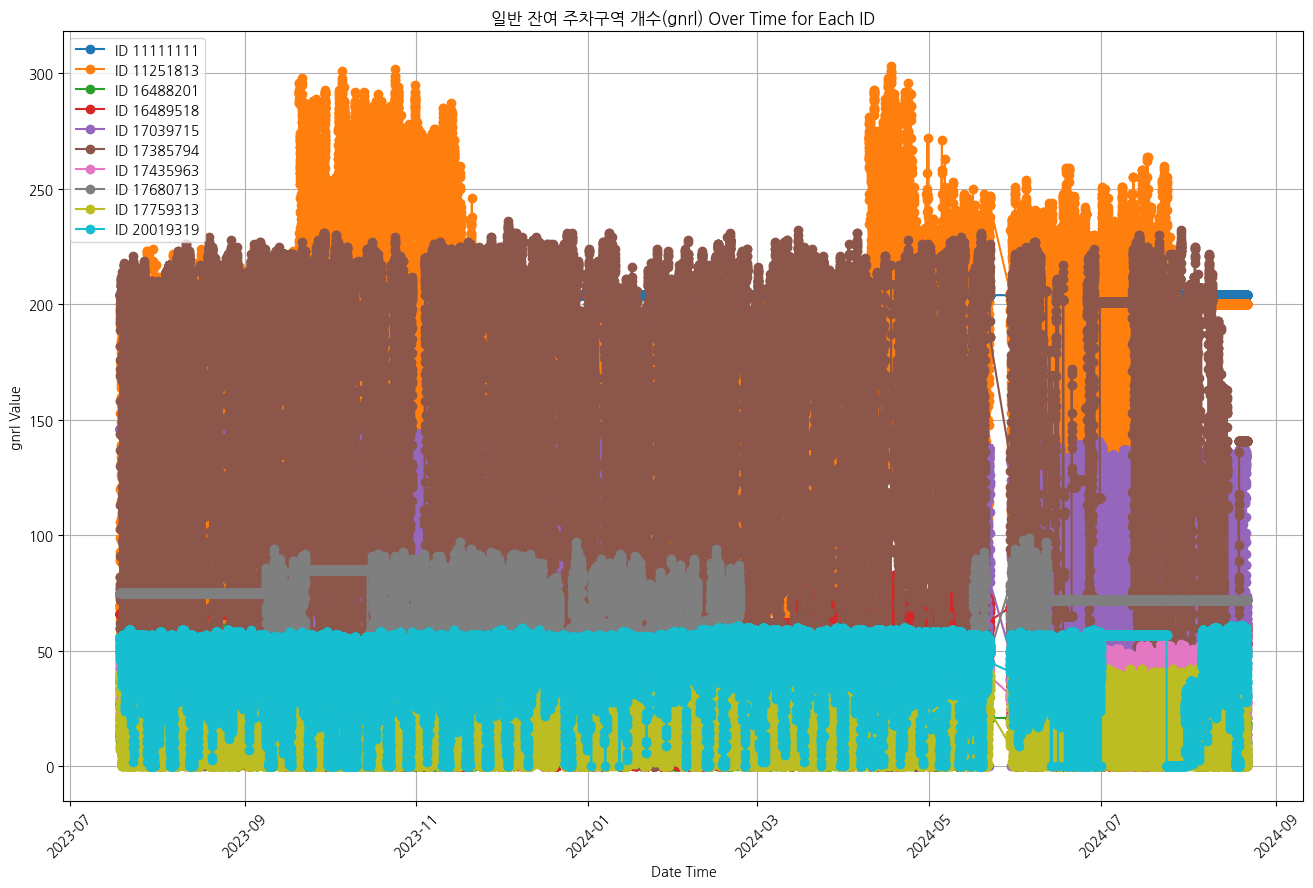

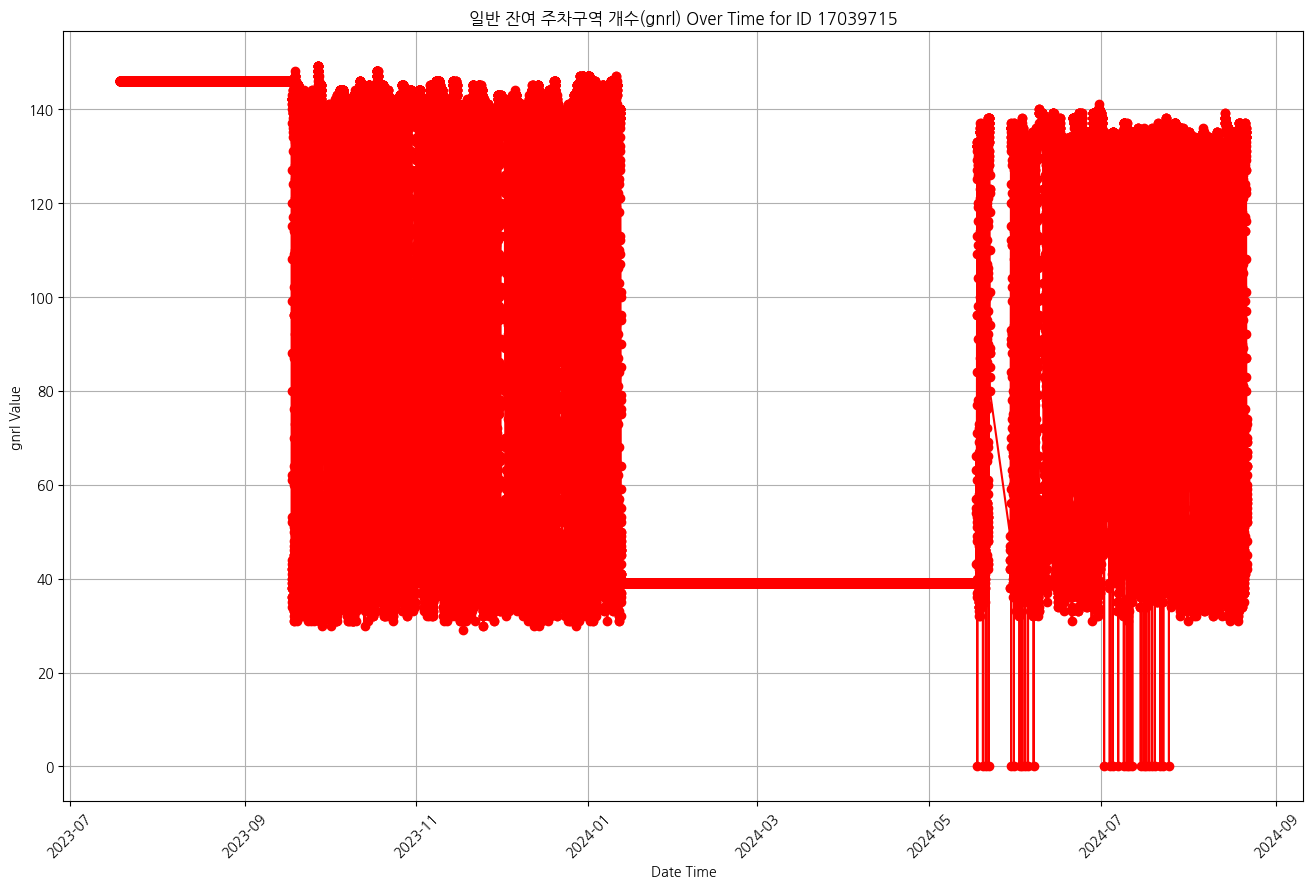

In [4]:
# id 별로 데이터 필터링 및 그래프 그리기
plt.figure(figsize=(16, 10))
for id_value in df['id'].unique():
    # id별로 데이터 필터링
    df_filtered = df[df['id'] == id_value]
    
    # date_time 순으로 정렬
    df_filtered = df_filtered.sort_values(by='date_time')
    
    # 그래프 그리기
    plt.plot(df_filtered['date_time'], df_filtered['gnrl'], marker='o', linestyle='-', label=f'ID {id_value}')

# 그래프 설정
plt.title('일반 잔여 주차구역 개수(gnrl) Over Time for Each ID')
plt.xlabel('Date Time')
plt.ylabel('gnrl Value')
plt.legend(loc='best')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

# id가 17039715인 그래프 추가로 그리기
df_17039715 = df[df['id'] == 17039715].sort_values(by='date_time')

plt.figure(figsize=(16, 10))
plt.plot(df_17039715['date_time'], df_17039715['gnrl'], marker='o', linestyle='-', color='red')
plt.title('일반 잔여 주차구역 개수(gnrl) Over Time for ID 17039715')
plt.xlabel('Date Time')
plt.ylabel('gnrl Value')
plt.grid(True)
plt.xticks(rotation=45)
plt.show()

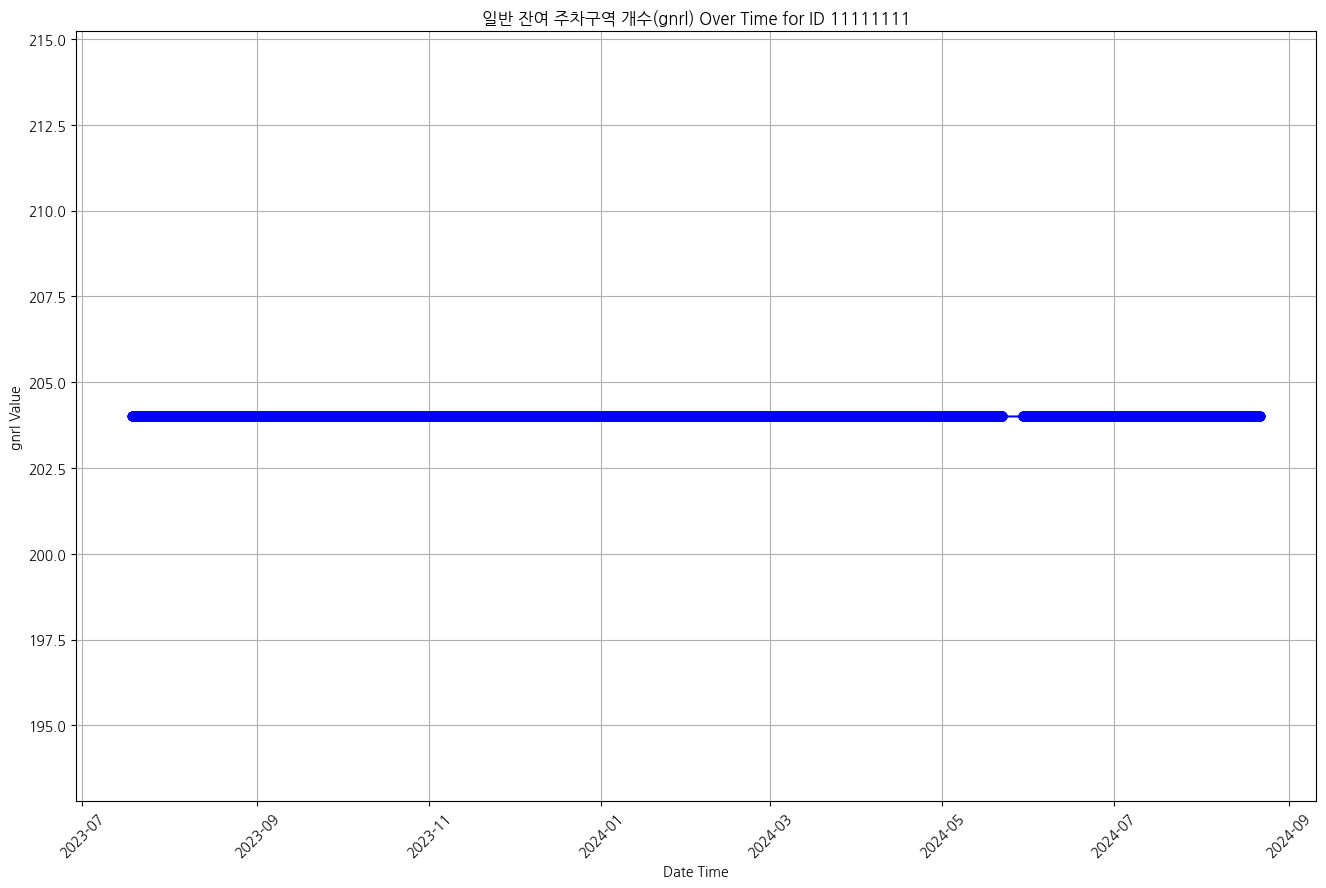

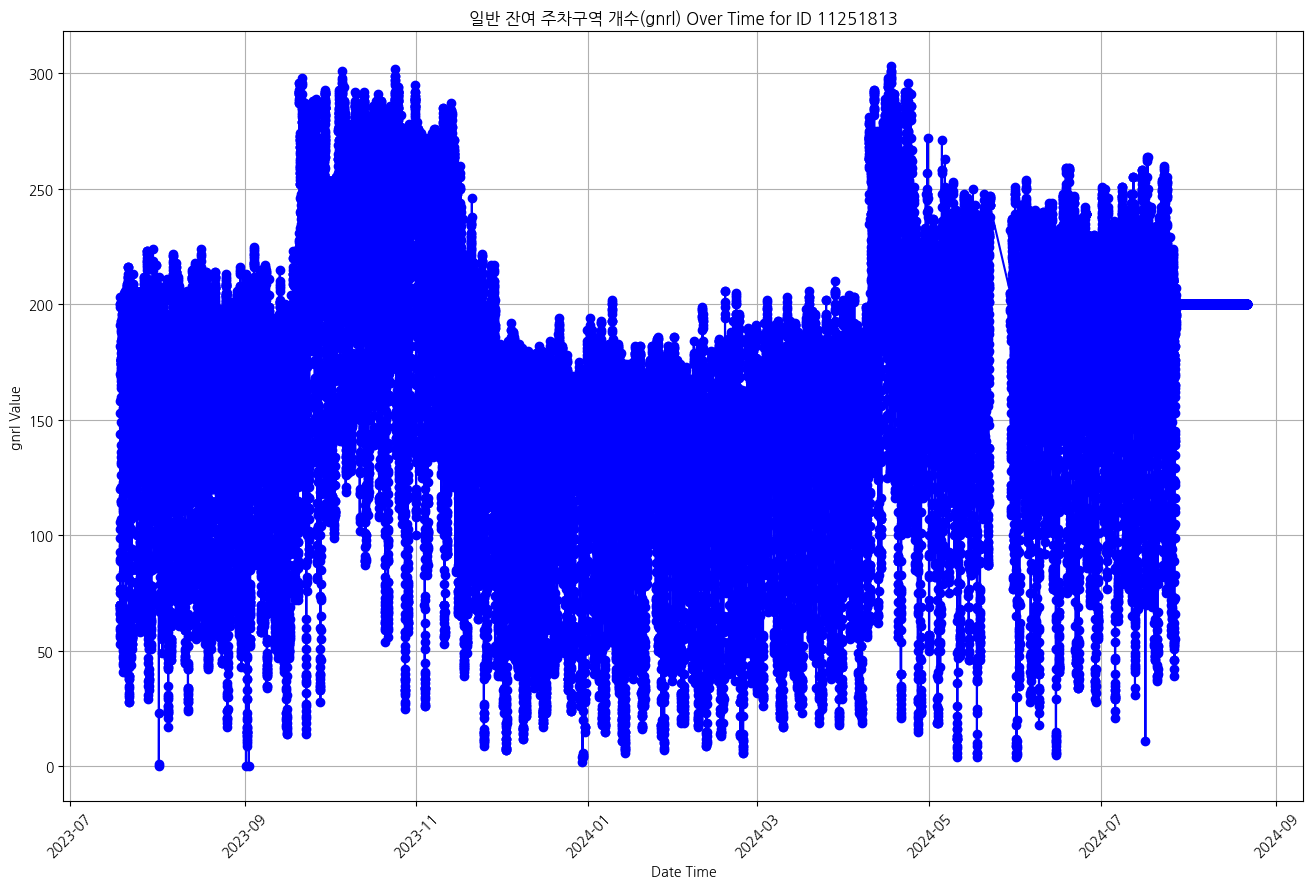

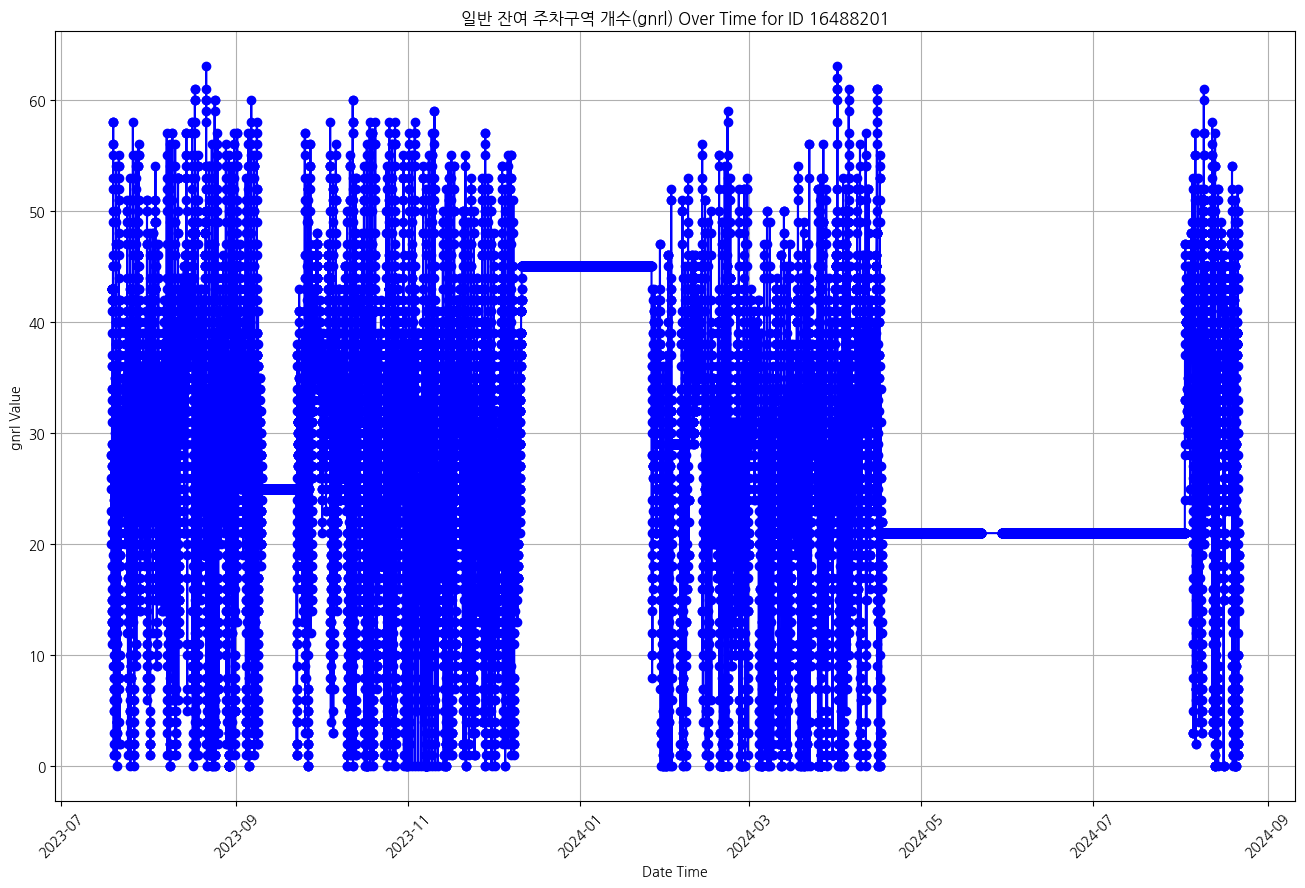

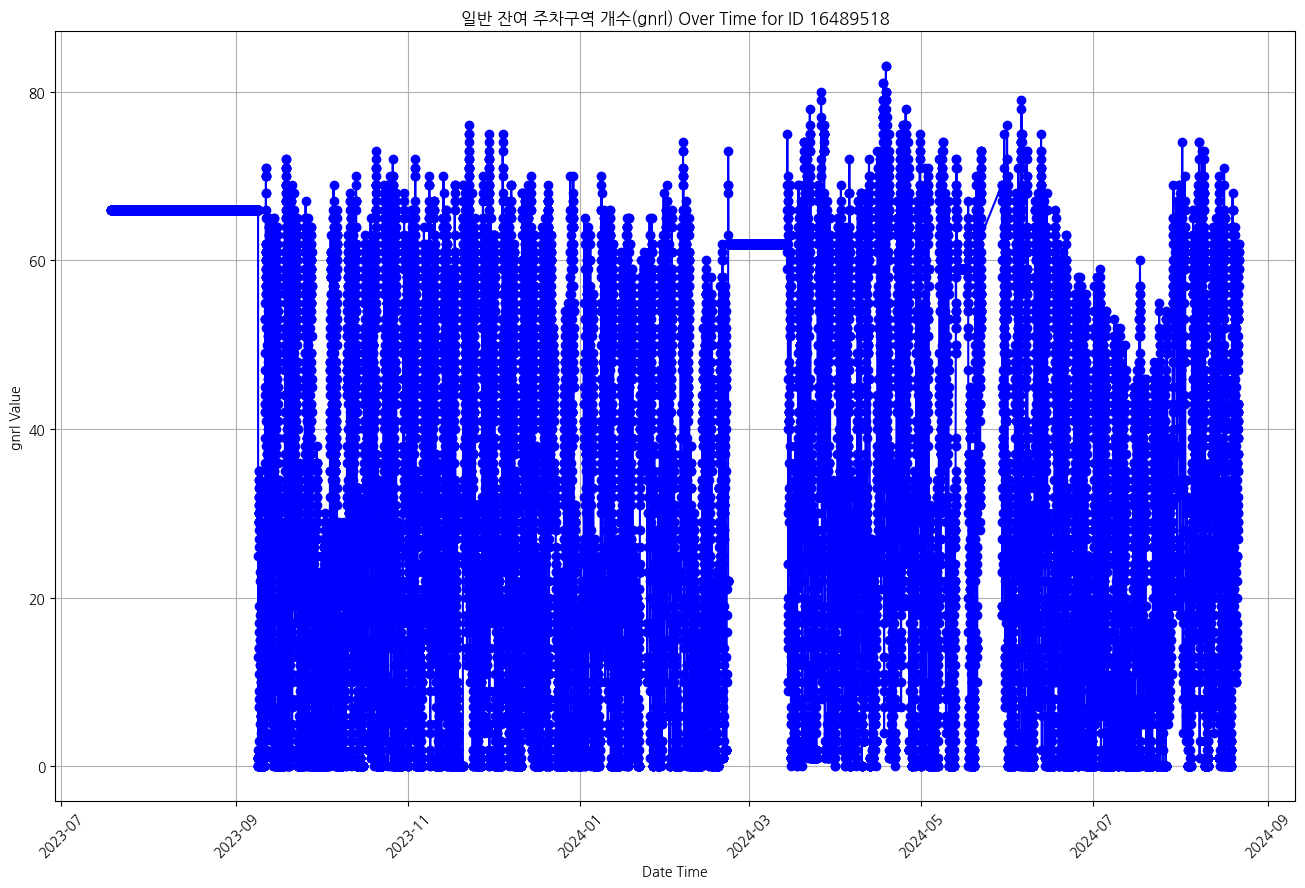

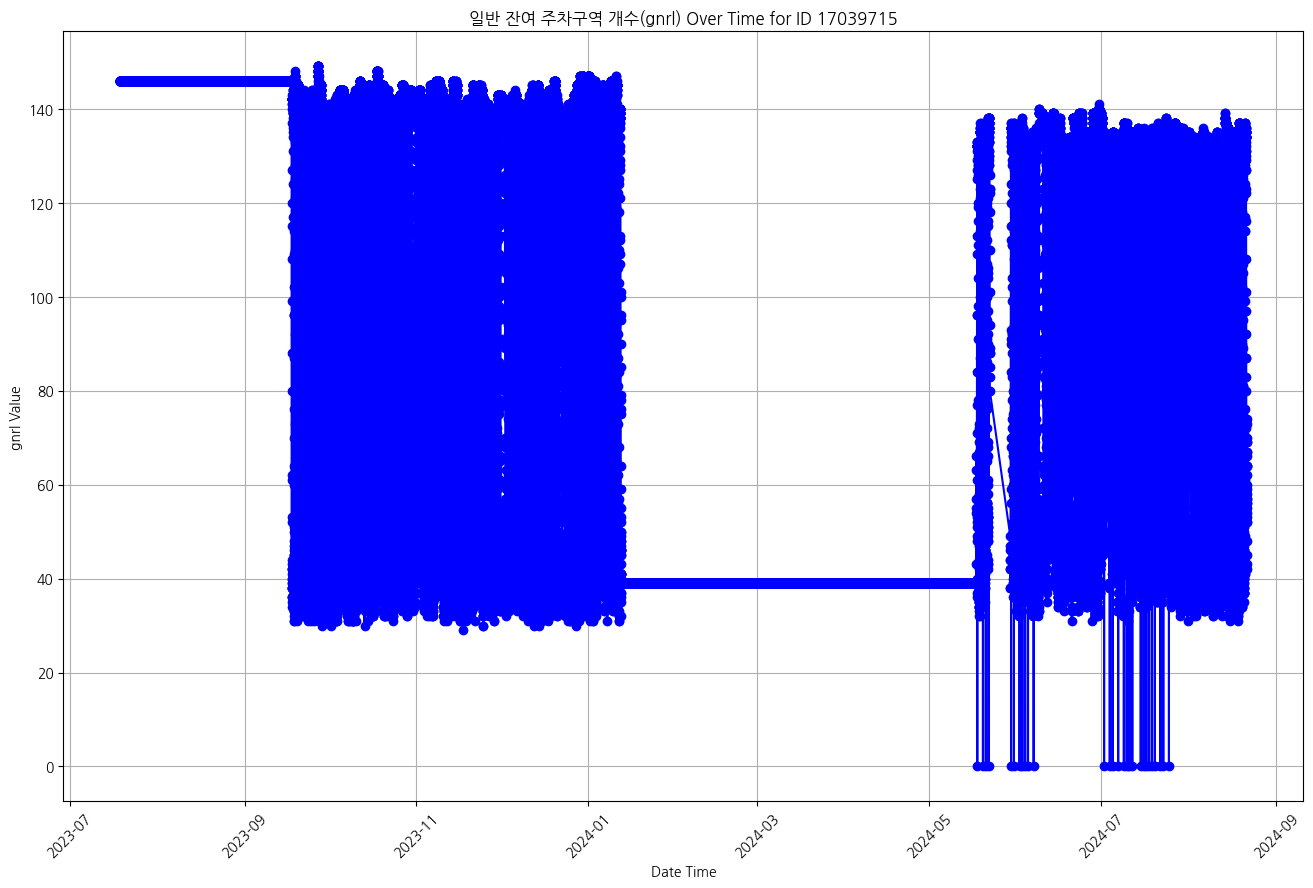

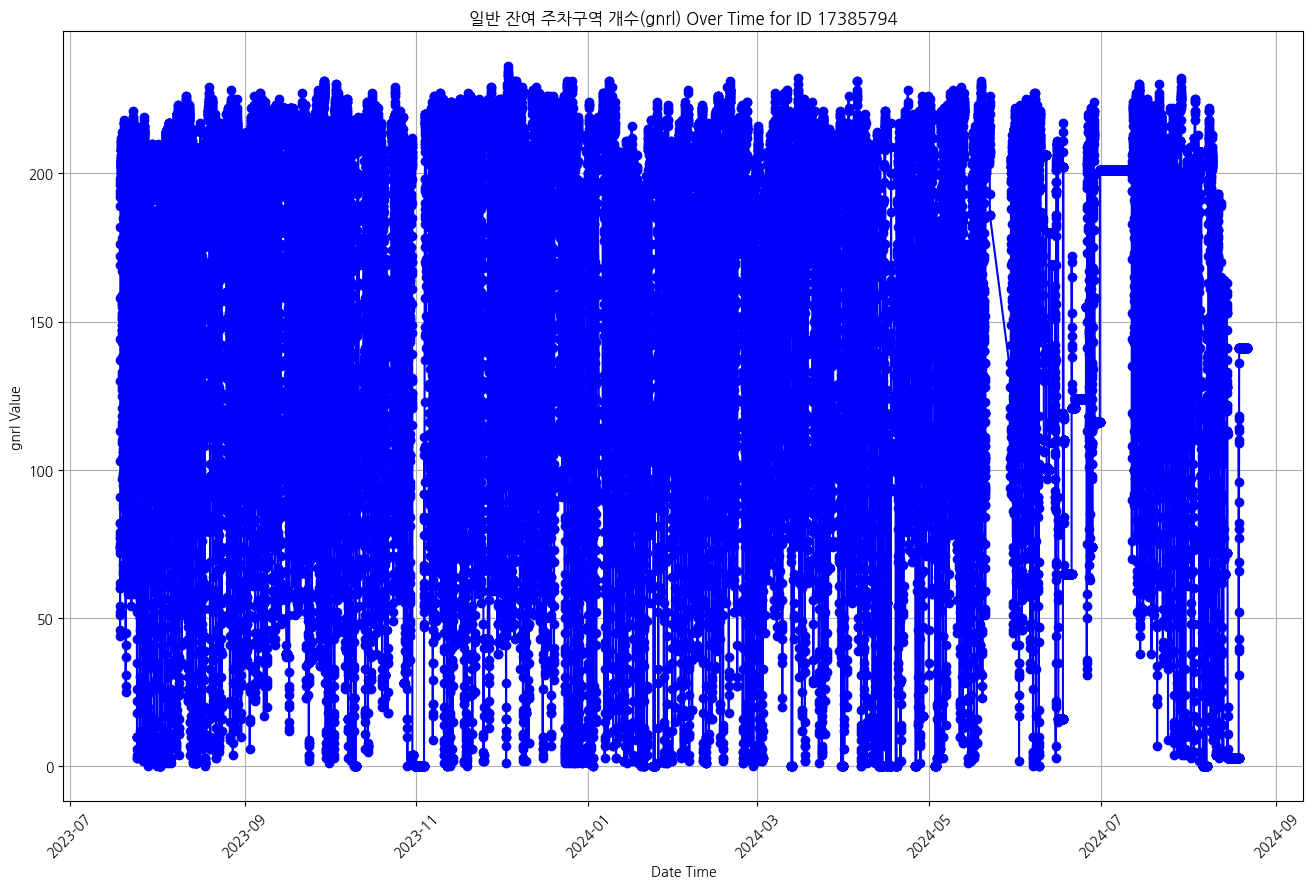

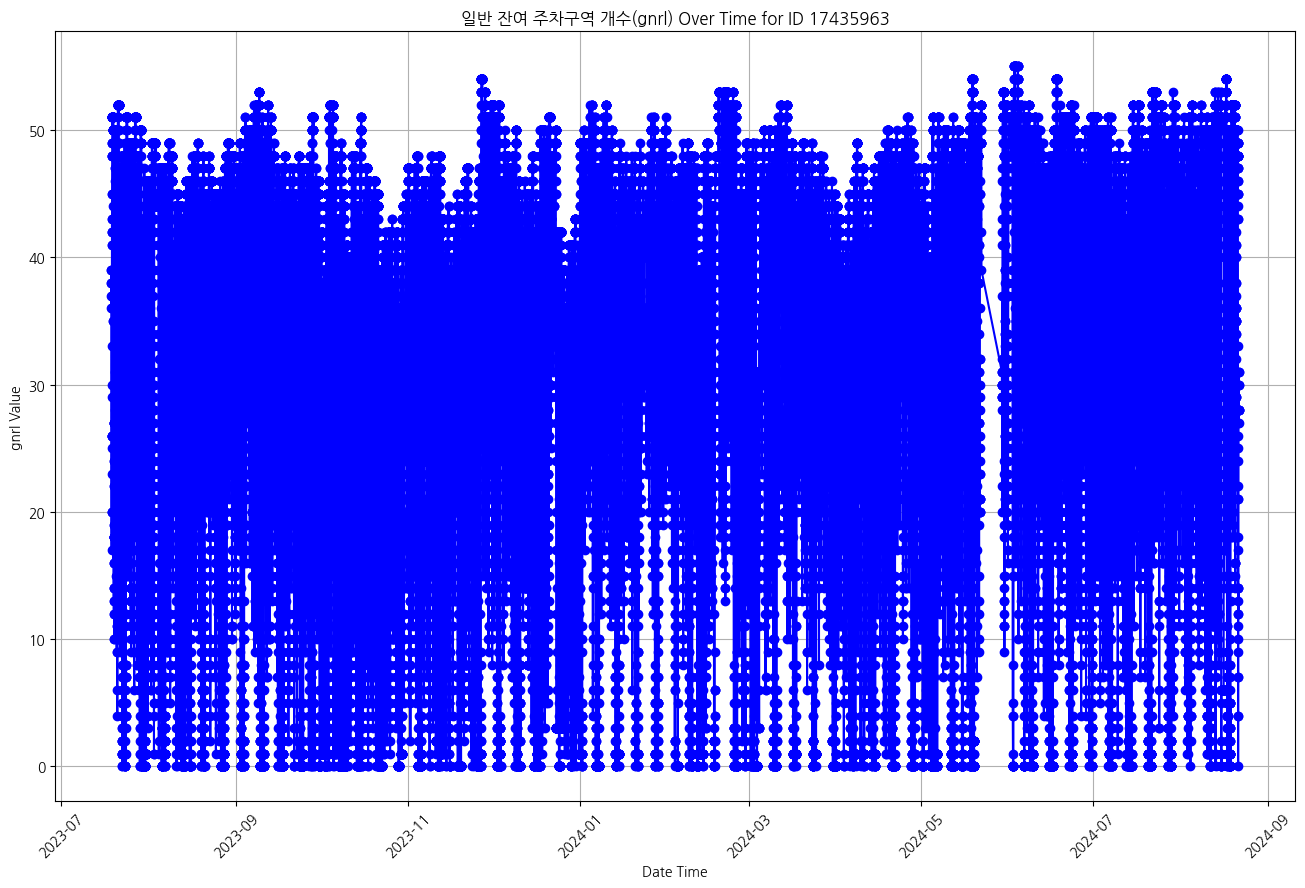

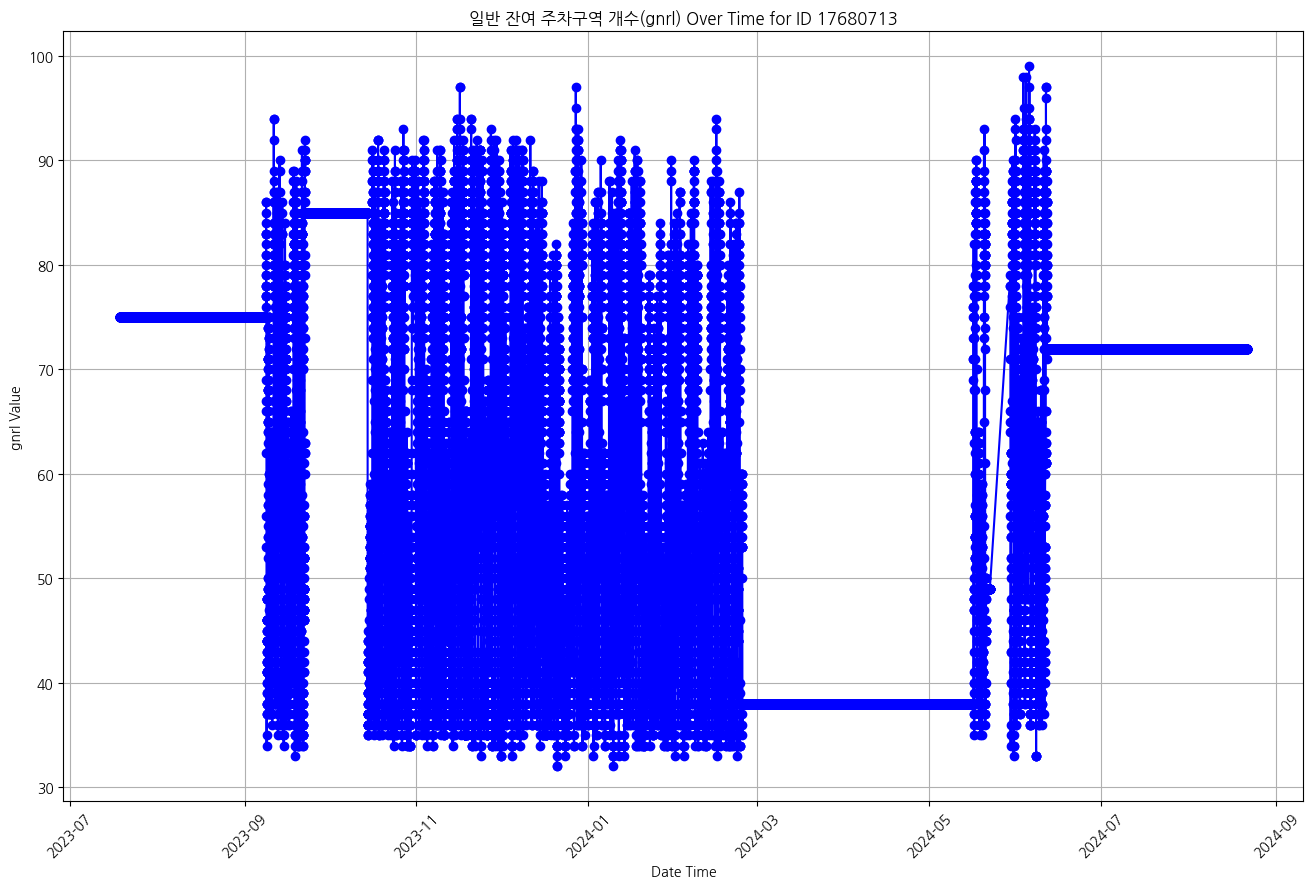

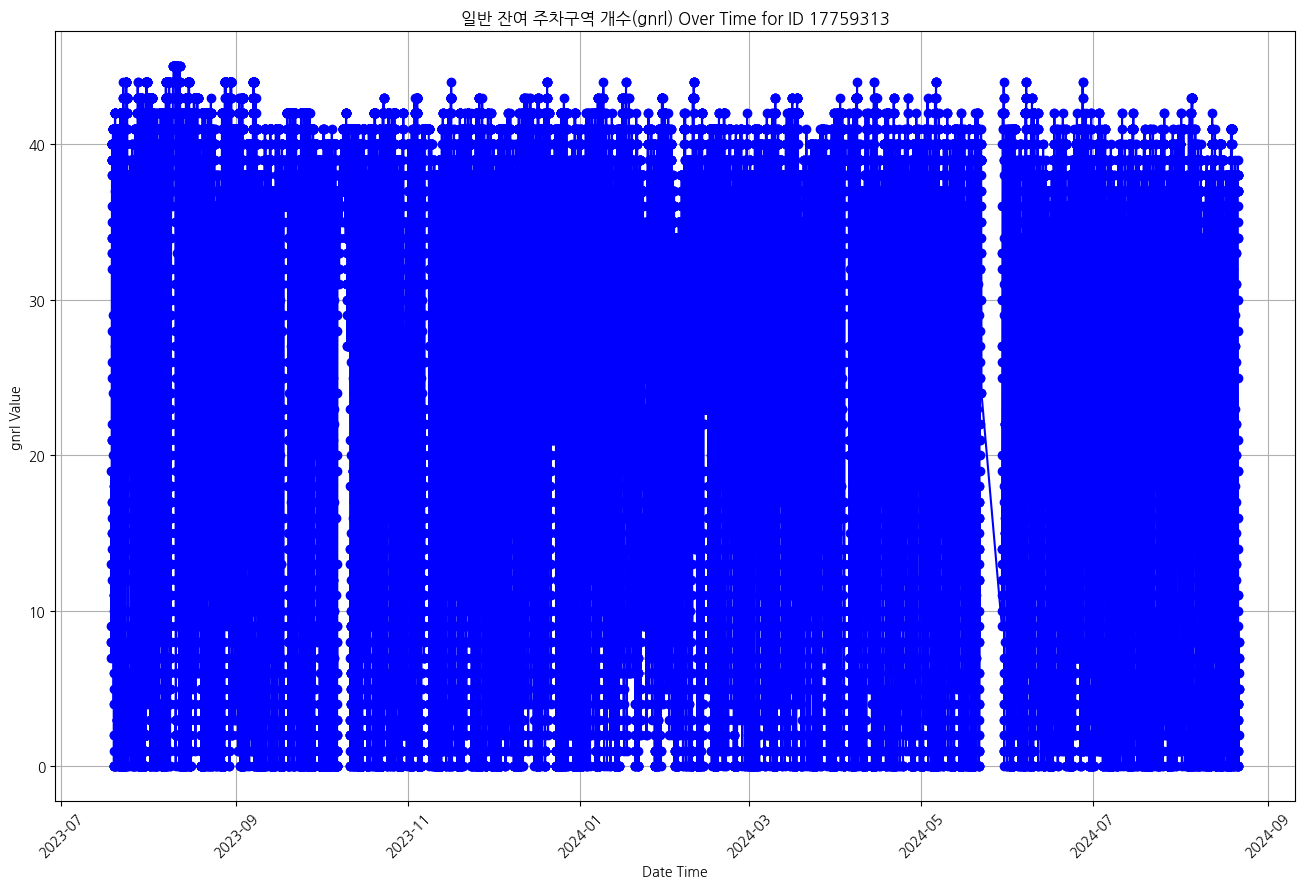

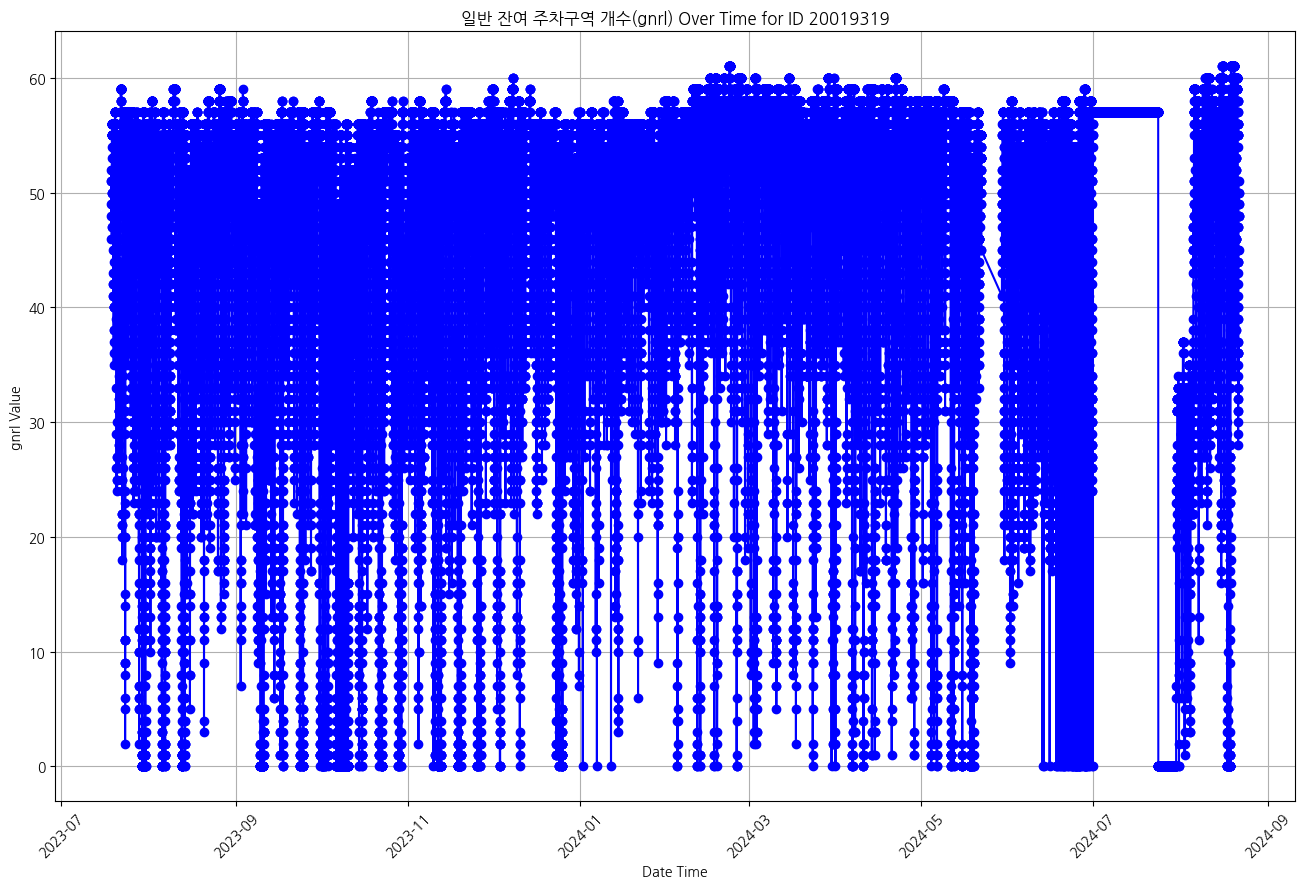

In [5]:
# id 별로 데이터 필터링 및 각각의 그래프 그리기
for id_value in df['id'].unique():
    # id별로 데이터 필터링
    df_filtered = df[df['id'] == id_value]
    
    # date_time 순으로 정렬
    df_filtered = df_filtered.sort_values(by='date_time')
    
    # 개별 그래프 그리기
    plt.figure(figsize=(16, 10))
    plt.plot(df_filtered['date_time'], df_filtered['gnrl'], marker='o', linestyle='-', color='blue')
    plt.title(f'일반 잔여 주차구역 개수(gnrl) Over Time for ID {id_value}')
    plt.xlabel('Date Time')
    plt.ylabel('gnrl Value')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.show()

In [ ]:
# id 별로 데이터 필터링 및 각각의 그래프 그리기
for id_value in df['id'].unique():
    # id별로 데이터 필터링
    df_filtered = df[df['id'] == id_value]
    
    # date_time 순으로 정렬
    df_filtered = df_filtered.sort_values(by='date_time')
    
    # 개별 그래프 그리기
    plt.figure(figsize=(16, 10))
    plt.plot(df_filtered['date_time'], df_filtered['gnrl'], marker='o', linestyle='-', color='blue')
    plt.title(f'일반 잔여 주차구역 개수(gnrl) Over Time for ID {id_value}')
    plt.xlabel('Date Time')
    plt.ylabel('gnrl Value')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.show()